# Drawing diagrams

A diagram as a graph: inline in Jupyter, as text, as a file, as Graphviz
DOT or Mermaid. Two examples: a control loop for feedback, and a transmitter
to receiver chain. One layout serves all: columns follow the signal flow,
feedback lines run dashed below.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig

import sigline as sl

## 1. A speed control loop

A motor's speed follows its drive with a time constant (a first-order
plant). A PI controller compares the measured speed with the set point and
drives the motor. The speed sensor adds one sample of delay, which also lets
the loop run vectorised in chunks of one sample.

| block | role |
| --- | --- |
| `setpoint` | wanted speed, a step |
| `error` | set point minus measured speed |
| `pi` | PI controller: $u[n] = u[n-1] + (k_p + k_i T)\,e[n] - k_p\,e[n-1]$ |
| `motor` | first-order plant, time constant 50 ms |
| `sensor` | one sample of measurement delay |

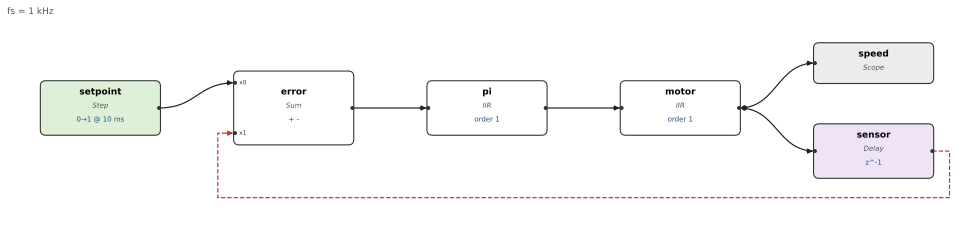

In [2]:
fs_c = 1000.0
kp, ki, a = 0.8, 40.0, np.exp(-1 / (0.05 * fs_c))

setpoint = sl.Step(0.01, name="setpoint")
error = sl.Sum("+-", name="error")
pi = sl.IIR(b=[kp + ki / fs_c, -kp], a=[1.0, -1.0], name="pi")
motor = sl.IIR(b=[1 - a], a=[1.0, -a], name="motor")
speed = sl.Scope("speed")

setpoint >> error["x0"]
error >> pi >> motor >> speed
motor >> sl.Delay(1, name="sensor") >> error["x1"]

loop = sl.Diagram(speed, fs=fs_c)
loop

The red dashed line is the feedback. As text:

In [3]:
print(loop)

Diagram  fs = 1 kHz  |  6 blocks, 6 lines, 1 feedback

signal flow:
  setpoint ──▶ error[x0]
  error ──▶ pi ──▶ motor
  motor ──▶ speed
  motor ──▶ sensor
feedback:
  sensor ══⟲══▶ error[x1]

blocks:
  [0] setpoint  Step   0→1 @ 10 ms
  [1] error     Sum    + -
  [2] pi        IIR    order 1
  [3] motor     IIR    order 1
  [4] speed     Scope
  [4] sensor    Delay  z^-1


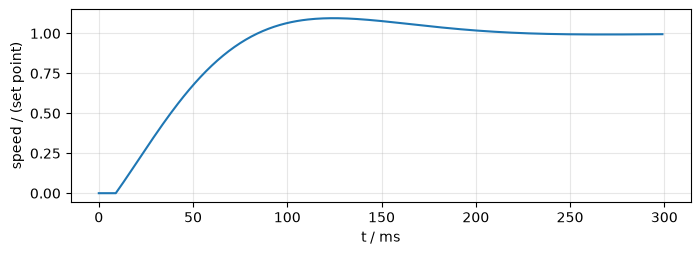

In [4]:
loop.run(0.3)
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(1e3 * speed.t, speed.data)
ax.set(xlabel="t / ms", ylabel="speed / (set point)")
ax.grid(alpha=0.3)
plt.show()

## 2. Transmitter to receiver

AM: a 1 kHz message rides on a 10 kHz carrier, noise is added on the way,
and the receiver takes the envelope (`abs`) and low-passes it. Operators
build the transmitter and the channel: `0.5 * message` is a `Gain`, `1 + ...`
a `Sum` with a `Const`, `+ noise` another `Sum`; `np.abs` after `>>` becomes
a `Func`.

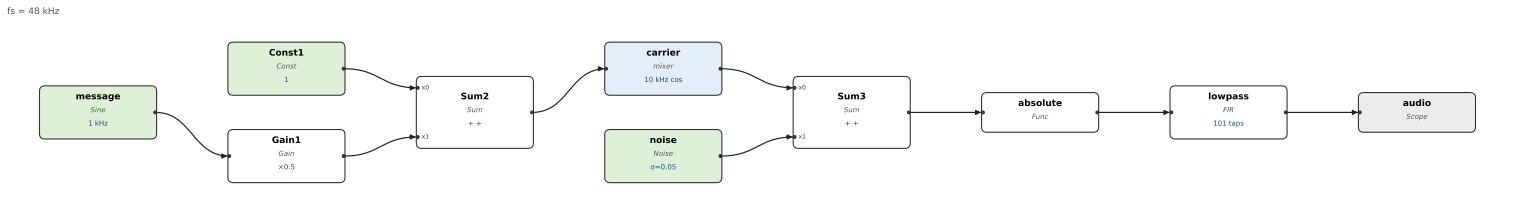

In [5]:
fs = 48_000.0
message = sl.Sine(1e3, name="message")
carrier = sl.mixer(10e3, name="carrier")
noise = sl.Noise(0.05, seed=1, name="noise")
lowpass = sl.FIR(sig.firwin(101, 3e3, fs=fs), name="lowpass")
audio = sl.Scope("audio")

tx = (1 + 0.5 * message) >> carrier  # AM transmitter
rx = tx + noise  # channel
rx >> np.abs >> lowpass >> audio  # envelope receiver

link = sl.Diagram(audio, fs=fs)
link

## Files

`d.draw(save=...)` writes any matplotlib format: PDF for documents, SVG for
the web, PNG for slides.

link.pdf 32504 bytes


link.svg 62335 bytes


link.png 65540 bytes


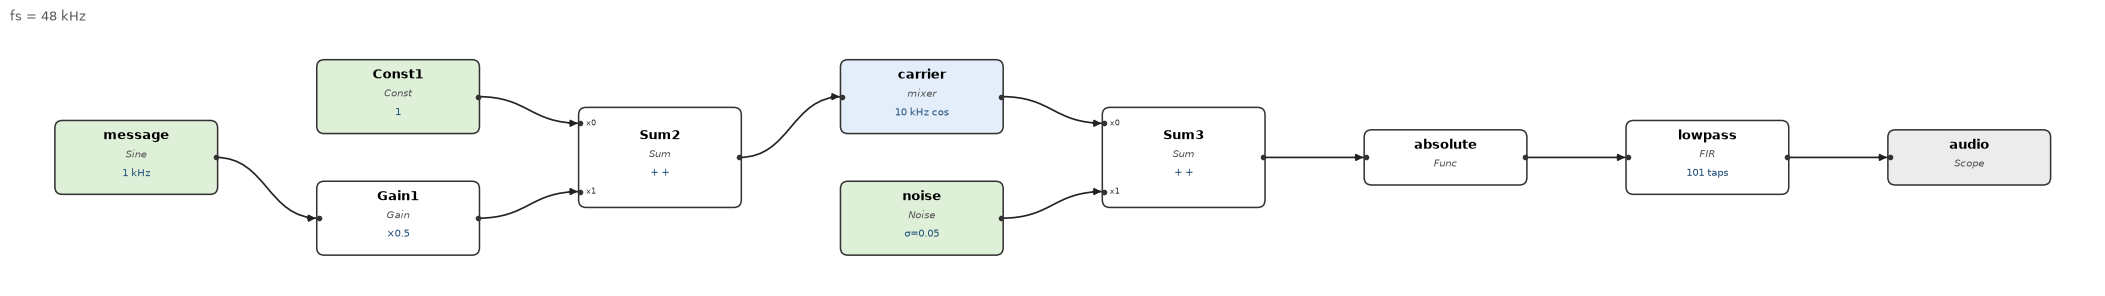

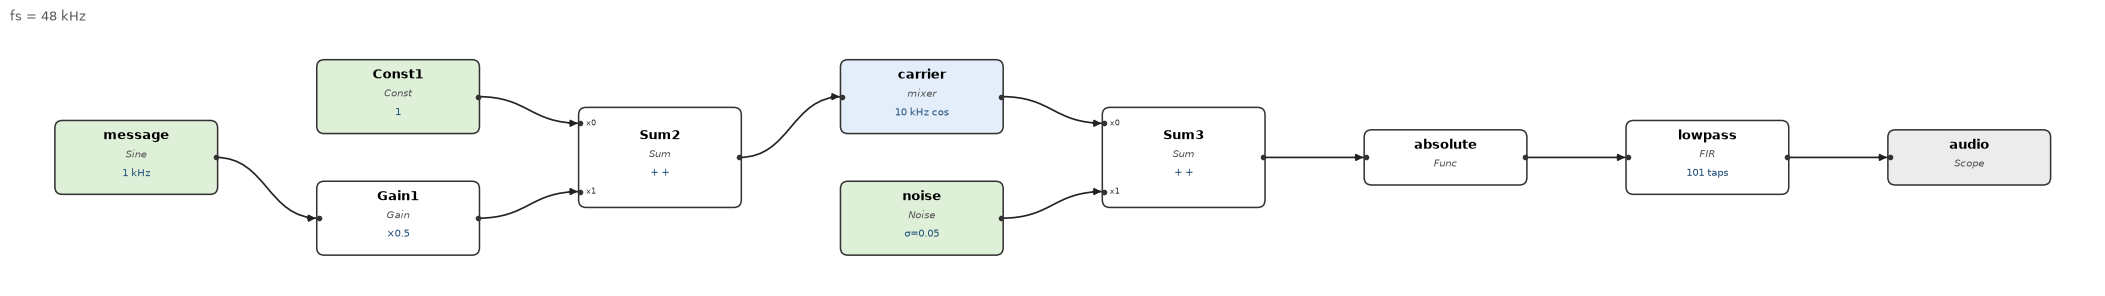

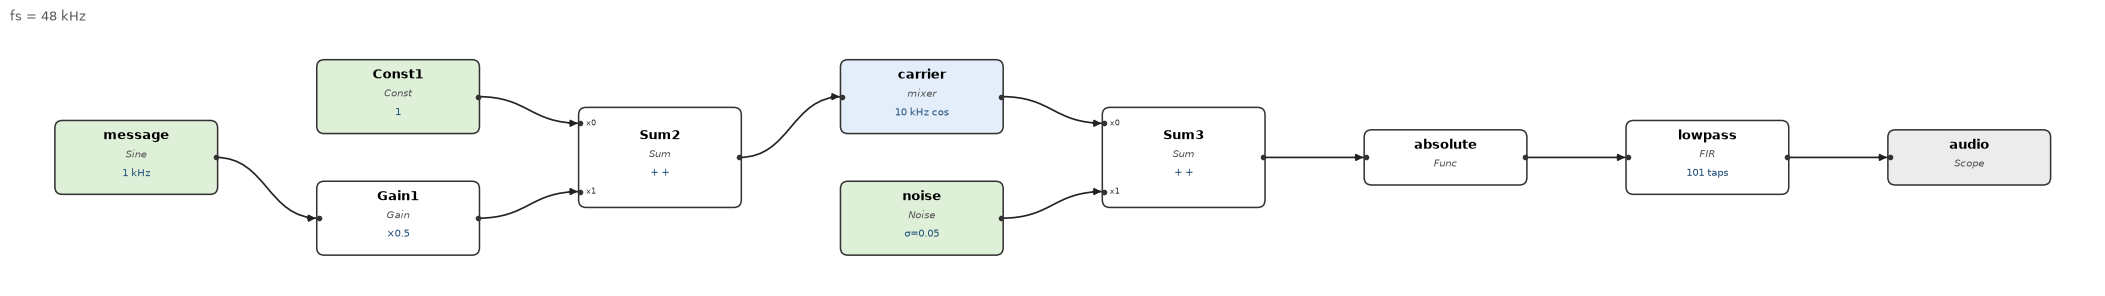

In [6]:
out = Path(tempfile.mkdtemp())
for name in ("link.pdf", "link.svg", "link.png"):
    link.draw(save=out / name)
    print(name, (out / name).stat().st_size, "bytes")

## Graphviz and Mermaid

`d.to_dot()` for `dot -Tpdf` or Typst's `diagraph` package; `d.to_mermaid()`
for Markdown on GitHub.

In [7]:
print(link.to_dot())

digraph sigline {
  rankdir=LR;
  splines=spline;
  node [shape=record, fontname="Helvetica", fontsize=10,
        style="rounded,filled"];
  edge [arrowsize=0.7];
  b7 [label="{message\nSine\n1 kHz|{<o_y> }}", fillcolor="#dff0d8"];
  b10 [label="{{<i_x> }|carrier\nmixer\n10 kHz cos|{<o_y> }}", fillcolor="#e3eefa"];
  b11 [label="{noise\nNoise\nσ=0.05|{<o_y> }}", fillcolor="#dff0d8"];
  b12 [label="{{<i_x> }|lowpass\nFIR\n101 taps|{<o_y> }}", fillcolor="#ffffff"];
  b13 [label="{{<i_x> }|audio\nScope}", fillcolor="#ececec"];
  b14 [label="{{<i_x> }|Gain1\nGain\n×0.5|{<o_y> }}", fillcolor="#ffffff"];
  b15 [label="{Const1\nConst\n1|{<o_y> }}", fillcolor="#dff0d8"];
  b16 [label="{{<i_x0> x0|<i_x1> x1}|Sum2\nSum\n+ +|{<o_y> }}", fillcolor="#ffffff"];
  b17 [label="{{<i_x0> x0|<i_x1> x1}|Sum3\nSum\n+ +|{<o_y> }}", fillcolor="#ffffff"];
  b18 [label="{{<i_x> }|absolute\nFunc|{<o_y> }}", fillcolor="#ffffff"];
  b7:o_y:e -> b14:i_x:w;
  b10:o_y:e -> b17:i_x0:w;
  b11:o_y:e -> b17:i_x1:w;
  b

In [8]:
print(link.to_mermaid())

flowchart LR
  message["message<br/><small>Sine</small>"]
  carrier["carrier<br/><small>mixer</small>"]
  noise["noise<br/><small>Noise</small>"]
  lowpass["lowpass<br/><small>FIR</small>"]
  audio["audio<br/><small>Scope</small>"]
  Gain1["Gain1<br/><small>Gain</small>"]
  Const1["Const1<br/><small>Const</small>"]
  Sum2["Sum2<br/><small>Sum</small>"]
  Sum3["Sum3<br/><small>Sum</small>"]
  absolute["absolute<br/><small>Func</small>"]
  message --> Gain1
  carrier -->|x0| Sum3
  noise -->|x1| Sum3
  lowpass --> audio
  Gain1 -->|x1| Sum2
  Const1 -->|x0| Sum2
  Sum2 --> carrier
  Sum3 --> absolute
  absolute --> lowpass
